In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

SEED = 42

LABELS = ["Low", "Mid", "High"]
LABEL_MAP = {"Low": 0, "Mid": 1, "High": 2}
PROB_COLS = ["p_Low", "p_Mid", "p_High"]

BUDGETS = [0, 20, 40, 60, 80, 100]

cwd = Path.cwd()

if (cwd / "splits" / "test.csv").exists():
    BASE = cwd
elif (cwd / "output" / "splits" / "test.csv").exists():
    BASE = cwd / "output"
else:
    raise FileNotFoundError(
        f"Không tìm thấy splits/test.csv. CWD={cwd}"
    )

DATA_DIR = BASE / "splits"
PROB_DIR = BASE / "section_4_2"

RESULT_DIR = BASE / "section_4_4"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", BASE.resolve())
print("Measurement budgets:", BUDGETS)
print("READY!")



Working directory: /Users/hgianee/Downloads/Maternal health risk data 2/output
Measurement budgets: [0, 20, 40, 60, 80, 100]
READY!


In [3]:

def load_adaptive_data(split_name):

    labels = pd.read_csv(
        DATA_DIR / f"{split_name}.csv",
        dtype={"row_id": str}
    )

    basic = pd.read_csv(
        PROB_DIR / f"basic_{split_name}_probs.csv",
        dtype={"row_id": str}
    )

    full = pd.read_csv(
        PROB_DIR / f"full_{split_name}_probs.csv",
        dtype={"row_id": str}
    )

    for name, frame in [
        ("labels", labels),
        ("basic", basic),
        ("full", full)
    ]:
        assert frame["row_id"].is_unique, (
            f"Duplicate row_id: {name}/{split_name}"
        )

    assert set(labels["row_id"]) == set(basic["row_id"])
    assert set(labels["row_id"]) == set(full["row_id"])

    merged = (
        labels[["row_id", "RiskLevel"]]
        .merge(
            basic[["row_id"] + PROB_COLS],
            on="row_id",
            validate="one_to_one"
        )
        .merge(
            full[["row_id"] + PROB_COLS],
            on="row_id",
            suffixes=("_basic", "_full"),
            validate="one_to_one"
        )
        .sort_values("row_id")
        .reset_index(drop=True)
    )

    p_basic = merged[
        [f"{c}_basic" for c in PROB_COLS]
    ].to_numpy(dtype=float)

    p_full = merged[
        [f"{c}_full" for c in PROB_COLS]
    ].to_numpy(dtype=float)

    for p in [p_basic, p_full]:
        assert np.isfinite(p).all()
        assert np.all((p >= 0) & (p <= 1))
        assert np.allclose(
            p.sum(axis=1), 1, atol=1e-6
        )

    y = merged["RiskLevel"].map(
        LABEL_MAP
    ).to_numpy(dtype=int)

    return {
        "frame": merged,
        "y": y,
        "basic": p_basic,
        "full": p_full,
        "row_ids": merged["row_id"].to_numpy()
    }


datasets = {
    name: load_adaptive_data(name)
    for name in ["policy_val", "test"]
}

assert len(datasets["policy_val"]["y"]) == 606
assert len(datasets["test"]["y"]) == 1212

for name, ds in datasets.items():
    print(
        name,
        "records:", len(ds["y"]),
        "| high-risk:", (ds["y"] == 2).sum()
    )

print("\nBASIC/FULL PROBABILITIES LOADED!")


policy_val records: 606 | high-risk: 201
test records: 1212 | high-risk: 403

BASIC/FULL PROBABILITIES LOADED!


In [4]:

test = datasets["test"]

basic_pred = test["basic"].argmax(axis=1)
full_pred = test["full"].argmax(axis=1)

basic_acc = accuracy_score(test["y"], basic_pred)
full_acc = accuracy_score(test["y"], full_pred)

basic_f1 = f1_score(
    test["y"], basic_pred, average="macro"
)

full_f1 = f1_score(
    test["y"], full_pred, average="macro"
)

full_cm = confusion_matrix(
    test["y"], full_pred, labels=[0, 1, 2]
)

expected_cm = np.array([
    [400, 0, 0],
    [2, 406, 1],
    [1, 3, 399]
])

print("Basic Accuracy:", round(basic_acc, 5))
print("Basic Macro-F1:", round(basic_f1, 5))
print("Full Accuracy:", round(full_acc, 5))
print("Full Macro-F1:", round(full_f1, 5))
print("\nFull Confusion Matrix:")
print(full_cm)

assert np.array_equal(full_cm, expected_cm)
assert np.isclose(basic_f1, 0.89385, atol=0.0001)
assert np.isclose(full_f1, 0.99423, atol=0.0001)

print("\nPASS: SAME XGBOOST PREDICTIONS AS SECTION 4.1!")


Basic Accuracy: 0.89521
Basic Macro-F1: 0.89385
Full Accuracy: 0.99422
Full Macro-F1: 0.99423

Full Confusion Matrix:
[[400   0   0]
 [  2 406   1]
 [  1   3 399]]

PASS: SAME XGBOOST PREDICTIONS AS SECTION 4.1!


In [5]:

STRATEGIES = [
    {"name": "Risk", "type": "risk", "alpha": 1.0},
    {"name": "Uncertainty", "type": "entropy", "alpha": 0.0},
    {"name": "Hybrid-25", "type": "hybrid", "alpha": 0.25},
    {"name": "Hybrid-50", "type": "hybrid", "alpha": 0.50},
    {"name": "Hybrid-75", "type": "hybrid", "alpha": 0.75}
]


def normalized_entropy(probs):
    probs = np.asarray(probs, dtype=float)

    entropy = -np.sum(
        probs * np.log(np.clip(probs, 1e-12, 1.0)),
        axis=1
    )

    return entropy / np.log(3)


def calculate_selection_score(p_basic, strategy):

    p_high = p_basic[:, 2]
    uncertainty = normalized_entropy(p_basic)

    if strategy["type"] == "risk":
        return p_high

    if strategy["type"] == "entropy":
        return uncertainty

    if strategy["type"] == "hybrid":
        alpha = strategy["alpha"]

        return (
            alpha * p_high
            + (1 - alpha) * uncertainty
        )

    raise ValueError("Unknown strategy")


print("SELECTION STRATEGIES:")

for strategy in STRATEGIES:
    print(
        strategy["name"],
        "| alpha =", strategy["alpha"]
    )


SELECTION STRATEGIES:
Risk | alpha = 1.0
Uncertainty | alpha = 0.0
Hybrid-25 | alpha = 0.25
Hybrid-50 | alpha = 0.5
Hybrid-75 | alpha = 0.75


In [6]:

def simulate_adaptive(ds, budget, strategy):

    n = len(ds["y"])

    assert 0 <= budget <= 100

    n_measure = int(
        np.floor(n * budget / 100 + 1e-9)
    )

    score = calculate_selection_score(
        ds["basic"], strategy
    )

    # Sort descending by score.
    # Tie-break ascending by row_id for reproducibility.
    ranking = np.lexsort(
        (ds["row_ids"], -score)
    )

    selected = np.zeros(n, dtype=bool)

    if n_measure > 0:
        selected[ranking[:n_measure]] = True

    # Selected -> FULL probabilities
    # Not selected -> BASIC probabilities
    p_adaptive = np.where(
        selected[:, None],
        ds["full"],
        ds["basic"]
    )

    assert selected.sum() == n_measure
    assert np.allclose(
        p_adaptive.sum(axis=1), 1.0,
        atol=1e-6
    )

    if budget == 0:
        assert np.allclose(
            p_adaptive, ds["basic"]
        )

    if budget == 100:
        assert np.allclose(
            p_adaptive, ds["full"]
        )

    return {
        "probabilities": p_adaptive,
        "selected": selected,
        "selection_score": score,
        "n_measured": n_measure
    }


# Kiểm tra thử ở B=40%
demo_strategy = STRATEGIES[0]

demo = simulate_adaptive(
    datasets["policy_val"],
    budget=40,
    strategy=demo_strategy
)

print("Strategy:", demo_strategy["name"])
print("Records:", len(datasets["policy_val"]["y"]))
print("Measured records:", demo["n_measured"])
print("Unmeasured records:",
      (~demo["selected"]).sum())

print("\nADAPTIVE SIMULATION READY!")


Strategy: Risk
Records: 606
Measured records: 242
Unmeasured records: 364

ADAPTIVE SIMULATION READY!


In [7]:

def evaluate_adaptive(ds, probabilities, selected):

    y_true = ds["y"]
    y_pred = probabilities.argmax(axis=1)

    correct = y_true == y_pred
    under = y_pred < y_true
    over = y_pred > y_true

    severe = np.abs(y_true - y_pred) == 2
    high_mask = y_true == 2

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro_F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "High_Risk_Recall": (
            ((y_pred == 2) & high_mask).sum()
            / high_mask.sum()
        ),

        "Ordinal_MAE": float(
            np.mean(np.abs(y_true - y_pred))
        ),

        "Total_Errors": int((~correct).sum()),
        "Undertriage": int(under.sum()),
        "Overtriage": int(over.sum()),
        "Severe_Errors": int(severe.sum()),

        "High_to_Low": int(
            ((y_true == 2) & (y_pred == 0)).sum()
        ),

        "High_Correct": int(
            ((y_true == 2) & (y_pred == 2)).sum()
        ),

        "High_Total": int(high_mask.sum()),

        "N_Measured": int(selected.sum()),
        "Measured_Percent": (
            selected.mean() * 100
        ),

        # Each selected case receives two measurements
        "Additional_Measurements": int(
            2 * selected.sum()
        ),

        "Measurements_Avoided_vs_Full": int(
            2 * (~selected).sum()
        )
    }


print("EVALUATION FUNCTION READY!")


EVALUATION FUNCTION READY!


In [8]:

validation_results = []

val_ds = datasets["policy_val"]

for strategy in STRATEGIES:

    for budget in BUDGETS:

        result = simulate_adaptive(
            val_ds,
            budget,
            strategy
        )

        metrics = evaluate_adaptive(
            val_ds,
            result["probabilities"],
            result["selected"]
        )

        validation_results.append({
            "Strategy": strategy["name"],
            "Alpha": strategy["alpha"],
            "Budget": budget,
            **metrics
        })


validation_df = pd.DataFrame(
    validation_results
)

display(
    validation_df[
        [
            "Strategy", "Budget",
            "N_Measured",
            "Macro_F1", "High_Risk_Recall",
            "Ordinal_MAE", "Severe_Errors"
        ]
    ].round(5)
)

validation_df.to_csv(
    RESULT_DIR / "adaptive_validation_all_strategies.csv",
    index=False
)

print("VALIDATION STRATEGY COMPARISON COMPLETED!")


,Strategy,Budget,N_Measured,Macro_F1,High_Risk_Recall,Ordinal_MAE,Severe_Errors
0,Risk,0,0,0.89508,0.79602,0.11386,6
1,Risk,20,121,0.89508,0.79602,0.11386,6
2,Risk,40,242,0.96704,0.94527,0.04455,7
3,Risk,60,363,0.97038,0.95522,0.04125,7
4,Risk,80,484,0.98021,0.96517,0.02475,3
5,Risk,100,606,0.98680,0.97015,0.01650,2
6,Uncertainty,0,0,0.89508,0.79602,0.11386,6
7,Uncertainty,20,121,0.96871,0.95025,0.04290,7
8,Uncertainty,40,242,0.98021,0.96517,0.02475,3
9,Uncertainty,60,363,0.98680,0.97015,0.01650,2


VALIDATION STRATEGY COMPARISON COMPLETED!


In [9]:

# Evaluate strategy quality over intermediate budgets only
intermediate = validation_df[
    validation_df["Budget"].isin([20, 40, 60, 80])
].copy()

strategy_summary = (
    intermediate.groupby(
        "Strategy", as_index=False
    )
    .agg(
        Mean_Macro_F1=("Macro_F1", "mean"),
        Mean_High_Recall=("High_Risk_Recall", "mean"),
        Mean_Ordinal_MAE=("Ordinal_MAE", "mean")
    )
    .sort_values(
        [
            "Mean_Macro_F1",
            "Mean_High_Recall",
            "Mean_Ordinal_MAE",
            "Strategy"
        ],
        ascending=[False, False, True, True]
    )
    .reset_index(drop=True)
)

display(strategy_summary.round(5))

selected_strategy_name = (
    strategy_summary.iloc[0]["Strategy"]
)

selected_strategy = next(
    s for s in STRATEGIES
    if s["name"] == selected_strategy_name
)

print("\nSELECTED ADAPTIVE STRATEGY:")
print(selected_strategy)

policy_metadata = {
    "section": "4.4 Adaptive Two-Stage Screening",
    "model_family": "XGBoost",
    "probability_source": (
        "Section 4.2 calibrated Basic and Full probabilities"
    ),
    "selection_split": "policy_val",
    "selection_uses_only": "Basic model probabilities",
    "selected_strategy": selected_strategy,
    "selection_rule": (
        "Highest mean Macro-F1 over B=20,40,60,80; "
        "then highest mean High-Risk Recall; "
        "then lowest mean Ordinal MAE"
    ),
    "measurement_budgets_percent": BUDGETS,
    "records_measured_rule": "floor(N * B / 100)",
    "additional_features": [
        "HbA1c",
        "FastingGlucose"
    ],
    "seed": SEED
}

with open(
    RESULT_DIR / "selected_adaptive_strategy.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        policy_metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

strategy_summary.to_csv(
    RESULT_DIR / "validation_strategy_ranking.csv",
    index=False
)

print("\nADAPTIVE STRATEGY LOCKED!")


,Strategy,Mean_Macro_F1,Mean_High_Recall,Mean_Ordinal_MAE
0,Uncertainty,0.98063,0.96393,0.02517
1,Hybrid-25,0.97528,0.95896,0.03300
2,Hybrid-50,0.96437,0.92786,0.04373
3,Hybrid-75,0.95481,0.91667,0.05363
4,Risk,0.95318,0.91542,0.05611



SELECTED ADAPTIVE STRATEGY:
{'name': 'Uncertainty', 'type': 'entropy', 'alpha': 0.0}

ADAPTIVE STRATEGY LOCKED!


In [10]:

test_ds = datasets["test"]

test_results = []
adaptive_outputs = {}

for budget in BUDGETS:

    output = simulate_adaptive(
        test_ds,
        budget,
        selected_strategy
    )

    adaptive_outputs[budget] = output

    metrics = evaluate_adaptive(
        test_ds,
        output["probabilities"],
        output["selected"]
    )

    test_results.append({
        "Budget": budget,
        **metrics
    })

test_budget_df = pd.DataFrame(test_results)

display(
    test_budget_df[
        [
            "Budget",
            "N_Measured",
            "Macro_F1",
            "High_Risk_Recall",
            "Ordinal_MAE",
            "Severe_Errors",
            "High_to_Low",
            "Additional_Measurements"
        ]
    ].round(5)
)

test_budget_df.to_csv(
    RESULT_DIR / "adaptive_test_budget_performance.csv",
    index=False
)

# Verify endpoints against Section 4.1
row_zero = test_budget_df.loc[
    test_budget_df["Budget"] == 0
].iloc[0]

row_full = test_budget_df.loc[
    test_budget_df["Budget"] == 100
].iloc[0]

assert np.isclose(
    row_zero["Macro_F1"], 0.89385,
    atol=0.0001
)

assert np.isclose(
    row_full["Macro_F1"], 0.99423,
    atol=0.0001
)

assert np.isclose(
    row_full["High_Risk_Recall"], 0.99007,
    atol=0.0001
)

print("\nENDPOINT VALIDATION PASSED!")
print("ADAPTIVE TEST EVALUATION COMPLETED!")


,Budget,N_Measured,Macro_F1,High_Risk_Recall,Ordinal_MAE,Severe_Errors,High_to_Low,Additional_Measurements
0,0,0,0.89385,0.76923,0.11386,11,11,0
1,20,242,0.97365,0.96278,0.03135,6,6,484
2,40,484,0.98681,0.97767,0.01568,3,3,968
3,60,727,0.99010,0.97767,0.01238,3,3,1454
4,80,969,0.99423,0.99007,0.00660,1,1,1938
5,100,1212,0.99423,0.99007,0.00660,1,1,2424



ENDPOINT VALIDATION PASSED!
ADAPTIVE TEST EVALUATION COMPLETED!


In [11]:

N_RANDOM_RUNS = 200

rng = np.random.default_rng(SEED)

random_results = []

n = len(test_ds["y"])

for budget in BUDGETS:

    n_measure = int(
        np.floor(n * budget / 100 + 1e-9)
    )

    for repetition in range(N_RANDOM_RUNS):

        selected = np.zeros(n, dtype=bool)

        if n_measure > 0:
            indexes = rng.choice(
                n,
                size=n_measure,
                replace=False
            )
            selected[indexes] = True

        p_random = np.where(
            selected[:, None],
            test_ds["full"],
            test_ds["basic"]
        )

        metrics = evaluate_adaptive(
            test_ds,
            p_random,
            selected
        )

        random_results.append({
            "Budget": budget,
            "Repetition": repetition,
            "Macro_F1": metrics["Macro_F1"],
            "High_Risk_Recall": metrics["High_Risk_Recall"],
            "Ordinal_MAE": metrics["Ordinal_MAE"]
        })


random_df = pd.DataFrame(random_results)

random_summary = (
    random_df.groupby(
        "Budget", as_index=False
    )
    .agg(
        Random_Macro_F1=("Macro_F1", "mean"),
        Random_High_Recall=("High_Risk_Recall", "mean"),
        Random_Ordinal_MAE=("Ordinal_MAE", "mean"),
        SD_Macro_F1=("Macro_F1", "std")
    )
)

display(random_summary.round(5))

random_df.to_csv(
    RESULT_DIR / "random_baseline_repetitions.csv",
    index=False
)

random_summary.to_csv(
    RESULT_DIR / "random_baseline_summary.csv",
    index=False
)

print("RANDOM BASELINE COMPLETED!")


,Budget,Random_Macro_F1,Random_High_Recall,Random_Ordinal_MAE,SD_Macro_F1
0,0,0.89385,0.76923,0.11386,0.00000
1,20,0.91420,0.81290,0.09261,0.00359
2,40,0.93483,0.85753,0.07058,0.00440
3,60,0.95422,0.90098,0.04988,0.00391
4,80,0.97445,0.94577,0.02797,0.00382
5,100,0.99423,0.99007,0.00660,0.00000


RANDOM BASELINE COMPLETED!


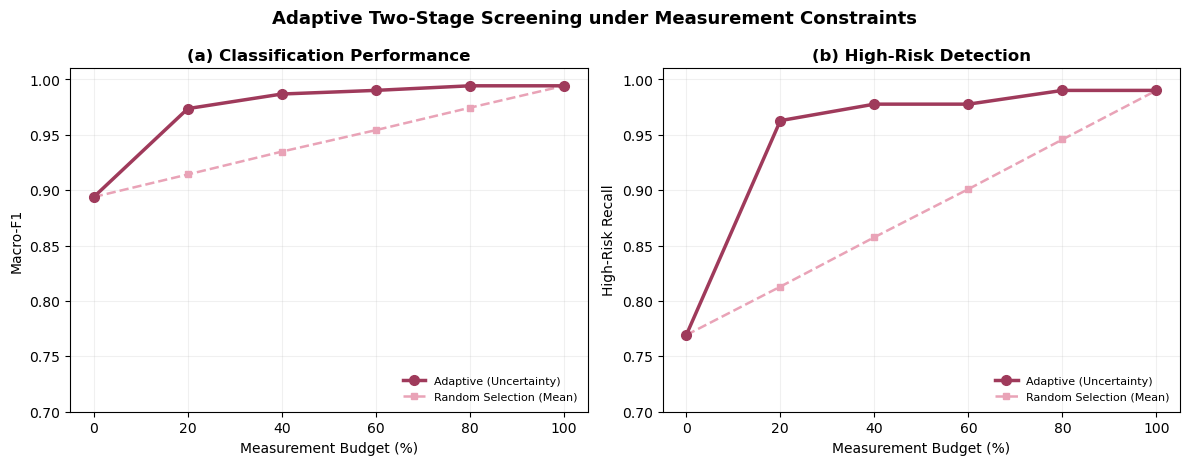

FIGURE SAVED!


In [12]:

# CELL 11 — Adaptive Screening Performance Figure

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.7),
    sharex=True
)

PINK_DARK = "#9F3A5B"
PINK_LIGHT = "#E9A3B7"

plot_specs = [
    (
        "Macro_F1",
        "Random_Macro_F1",
        "Macro-F1",
        "(a) Classification Performance"
    ),
    (
        "High_Risk_Recall",
        "Random_High_Recall",
        "High-Risk Recall",
        "(b) High-Risk Detection"
    )
]

for ax, (metric, random_metric, ylabel, title) in zip(
    axes, plot_specs
):

    ax.plot(
        test_budget_df["Budget"],
        test_budget_df[metric],
        marker="o",
        markersize=7,
        linewidth=2.5,
        color=PINK_DARK,
        label=f"Adaptive ({selected_strategy_name})",
        zorder=3
    )

    ax.plot(
        random_summary["Budget"],
        random_summary[random_metric],
        marker="s",
        markersize=5,
        linestyle="--",
        linewidth=1.8,
        color=PINK_LIGHT,
        label="Random Selection (Mean)"
    )

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Measurement Budget (%)")
    ax.set_ylabel(ylabel)

    ax.set_xticks(BUDGETS)
    ax.set_ylim(0.70, 1.01)
    ax.grid(alpha=0.18)

    ax.legend(
        frameon=False,
        fontsize=8,
        loc="lower right"
    )

fig.suptitle(
    "Adaptive Two-Stage Screening under Measurement Constraints",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "adaptive_budget_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("FIGURE SAVED!")


In [19]:

# CELL 12 — Export Adaptive Probabilities (FIXED)

import numpy as np
import pandas as pd

all_exports = {}

for split_name in ["policy_val", "test"]:

    ds = datasets[split_name]
    n_records = len(ds["y"])

    split_exports = []

    for budget in BUDGETS:

        output = simulate_adaptive(
            ds,
            budget,
            selected_strategy
        )

        p = output["probabilities"]
        pred = p.argmax(axis=1)

        export = pd.DataFrame({
            "row_id": ds["row_ids"],
            "RiskLevel": np.array(LABELS)[ds["y"]],
            "Budget": budget,
            "Strategy": selected_strategy_name,

            "Selected_For_Measurement": (
                output["selected"]
            ),

            "Basic_Selection_Score": (
                output["selection_score"]
            ),

            "Basic_Entropy": normalized_entropy(
                ds["basic"]
            ),

            "p_Low": p[:, 0],
            "p_Mid": p[:, 1],
            "p_High": p[:, 2],

            "Prediction_Argmax": (
                np.array(LABELS)[pred]
            )
        })

        # FIX: Check record count, not dict length
        assert len(export) == n_records

        assert export["row_id"].is_unique

        assert np.array_equal(
            export["row_id"].to_numpy(),
            ds["row_ids"]
        )

        assert np.allclose(
            export[PROB_COLS].sum(axis=1),
            1.0,
            atol=1e-6
        )

        assert (
            export["Selected_For_Measurement"].sum()
            == output["n_measured"]
        )

        # Save each budget
        filename = (
            f"adaptive_{split_name}_B{budget}.csv"
        )

        export.to_csv(
            RESULT_DIR / filename,
            index=False
        )

        split_exports.append(export)

        print(
            f"SAVED: {filename} "
            f"({len(export)} records)"
        )

    # Combine all budgets
    combined = pd.concat(
        split_exports,
        ignore_index=True
    )

    assert len(combined) == (
        n_records * len(BUDGETS)
    )

    assert not combined.duplicated(
        ["Budget", "row_id"]
    ).any()

    combined_filename = (
        f"adaptive_{split_name}_predictions_long.csv"
    )

    combined.to_csv(
        RESULT_DIR / combined_filename,
        index=False
    )

    all_exports[split_name] = combined

    print(
        f"\nCOMPLETED {split_name}: "
        f"{len(combined)} rows\n"
    )

print("=" * 50)
print("ALL ADAPTIVE PROBABILITIES EXPORTED!")
print("Output:", RESULT_DIR.resolve())


SAVED: adaptive_policy_val_B0.csv (606 records)
SAVED: adaptive_policy_val_B20.csv (606 records)
SAVED: adaptive_policy_val_B40.csv (606 records)
SAVED: adaptive_policy_val_B60.csv (606 records)
SAVED: adaptive_policy_val_B80.csv (606 records)
SAVED: adaptive_policy_val_B100.csv (606 records)

COMPLETED policy_val: 3636 rows

SAVED: adaptive_test_B0.csv (1212 records)
SAVED: adaptive_test_B20.csv (1212 records)
SAVED: adaptive_test_B40.csv (1212 records)
SAVED: adaptive_test_B60.csv (1212 records)
SAVED: adaptive_test_B80.csv (1212 records)
SAVED: adaptive_test_B100.csv (1212 records)

COMPLETED test: 7272 rows

ALL ADAPTIVE PROBABILITIES EXPORTED!
Output: /Users/hgianee/Downloads/Maternal health risk data 2/output/section_4_4


In [20]:

# CELL 13 — Final Audit

for split_name, ds in datasets.items():

    previous_selection = set()

    for budget in BUDGETS:

        output = simulate_adaptive(
            ds, budget, selected_strategy
        )

        selected_ids = set(
            ds["row_ids"][output["selected"]]
        )

        assert previous_selection.issubset(
            selected_ids
        ), "Measurement selections are not nested!"

        previous_selection = selected_ids

        assert output["n_measured"] == int(
            np.floor(len(ds["y"]) * budget / 100 + 1e-9)
        )

    print(
        f"PASS: {split_name} "
        "- consistent budget and nested selection"
    )

# Verify Test endpoint predictions
test_export = all_exports["test"]

for budget, reference in [
    (0, test_ds["basic"]),
    (100, test_ds["full"])
]:

    subset = test_export[
        test_export["Budget"] == budget
    ].sort_values("row_id")

    assert np.allclose(
        subset[PROB_COLS].to_numpy(),
        reference
    )

print("\nALL CHECKS PASSED!")
print("Selected strategy:", selected_strategy_name)
print("Output folder:", RESULT_DIR.resolve())


PASS: policy_val - consistent budget and nested selection
PASS: test - consistent budget and nested selection

ALL CHECKS PASSED!
Selected strategy: Uncertainty
Output folder: /Users/hgianee/Downloads/Maternal health risk data 2/output/section_4_4
